# Responsiveness schema v6 — a guided tour

This notebook walks through every table of the responsiveness schema on real data and shows what each
one answers. It reads the **test schema `tobiasr_responsiveness_v6`** (pilot, 2026-11-15) and the
production pipeline schemas, read-only.

**Pilot data** (ROS-1841, curation 2 of paramset 10, the curations the v1-drift-audit used):

| scan | stimulus | onsets |
|---|---|---|
| `scan9FOW97IH` | moving gratings, 12 directions × 15 repeats, 3 s on / 4 s off | 180 |
| `scan9FOWAIBH` | natural images; the 100 images shown 10× (3,900 singles not used here) | 1,000 |
| `scan9FOTBBSU` | appearing checkerboard (RF mapping), azimuth × elevation grid | |

Three trace types per curation: **dF/F0** (recipe 2), **CASCADE 25 ms** (spike rate) and **OASIS**
(suite2p deconvolution).

## The schema in one picture

```
                                   UNIVERSAL, event-independent
imaging.Fluorescence ──► Quality(.Cell)              raw F: detector gain, neuropil sweep, kurtosis, photons/s
        │           └──► TraceQuality(.Cell)  ◄── TraceSource (dF/F0 recipe | extraction method)
        │                                          SNR, noise, event rate, max value
        │                          UNIVERSAL, event-dependent
        ├── × TraceSource × EventSet × ReadoutParamSet ──► Readout(.Cell, .Condition)
        │        PSTH read-out per onset (trial_resp), test, effect, oracle, preferred condition
        └── × TraceSource × EventSet × ZetaParamSet ─────► Zeta(.Cell, .Condition)
                 ZETA p / z / latency, per-condition p
                                   STIMULUS-SPECIFIC
Readout × TuningParamSet ──► DirectionTuning(.Cell)   Mazurek, Kager & Van Hooser 2014 measures
                                   PARADIGM
trial.TrialEvent ──► EventSet.Onset ◄── EventSelector  (which events, condition parser, random control)
CellRule (thresholds) ──► cells(rule): is_qc / is_active / is_responsive / is_specific / is_reliable
```

Every result row carries the curation key, `trace_source`, and per cell `mask, fluo_channel`; event-dependent
rows add `event_selector` and their parameter set. Variants never overwrite each other.

In [1]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import datajoint as dj

_conf = os.path.expanduser("~/adamacs_ingest/dj_local_conf.json")     # lab config (host, user); not part of this notebook
if os.path.exists(_conf): dj.config.load(_conf)
dj.config["database.use_tls"] = False
dj.config["display.limit"] = 8
dj.conn().query("SET SESSION transaction_read_only = 1")          # read-only guard, enforced by the server
assert dj.conn().query("SELECT @@transaction_read_only").fetchone()[0] == 1

vm = lambda n: dj.create_virtual_module(n, n, create_schema=False, create_tables=False)
r, imaging, event, trial = vm("tobiasr_responsiveness_v6"), vm("roselab_imaging"), vm("roselab_event"), vm("roselab_trial")

# --- look -----------------------------------------------------------------------------------------
mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False, "legend.frameon": False,
                     "font.family": "DejaVu Sans", "axes.labelcolor": "#333", "xtick.color": "#555", "ytick.color": "#555"})
COL = {"dff0_r2": "#2b2d42", "cascade25": "#e76f51", "oasis": "#2a9d8f", "stim": "#ffd166", "base": "#8ecae6",
       "resp": "#ef476f", "null": "#adb5bd", "accent": "#7b2cbf"}
LBL = {"dff0_r2": "dF/F0 (recipe 2)", "cascade25": "CASCADE 25 ms", "oasis": "OASIS (suite2p)"}

GRAT, IMG, RF = "scan9FOW97IH", "scan9FOWAIBH", "scan9FOTBBSU"
def cur(scan):  # the curation the pilot used
    return (r.ResponseTask & {"scan_id": scan}).fetch("session_id", "scan_id", "paramset_idx", "curation_id", as_dict=True, limit=1)[0]
CUR = {s: cur(s) for s in (GRAT, IMG, RF)}
CUR

[2026-11-16 01:53:51,352][INFO]: DataJoint is configured from /home/backup_user/adamacs_ingest/dj_local_conf.json


{'scan9FOW97IH': {'session_id': 'sess9FOW97IH',
  'scan_id': 'scan9FOW97IH',
  'paramset_idx': np.int64(10),
  'curation_id': np.int64(2)},
 'scan9FOWAIBH': {'session_id': 'sess9FOWAIBH',
  'scan_id': 'scan9FOWAIBH',
  'paramset_idx': np.int64(10),
  'curation_id': np.int64(2)},
 'scan9FOTBBSU': {'session_id': 'sess9FOTBBSU',
  'scan_id': 'scan9FOTBBSU',
  'paramset_idx': np.int64(10),
  'curation_id': np.int64(1)}}

In [2]:
# helpers: traces, onsets, peri-event matrices -----------------------------------------------------
def frame_times(k):
    return (event.Event & {"session_id": k["session_id"], "scan_id": k["scan_id"]} & 'event_type LIKE "%%2p_frames%%"').fetch(
        "event_start_time", order_by="event_start_time").astype(float)

def trace(k, mask, source):
    src = (r.TraceSource & {"trace_source": source}).fetch1()
    kk = {**{a: k[a] for a in ("session_id", "scan_id", "paramset_idx", "curation_id")}, "mask": int(mask), "fluo_channel": 0}
    if src["extraction_method"]:
        return np.asarray((imaging.Activity.Trace & kk & {"extraction_method": src["extraction_method"]}).fetch1("activity_trace"), float)
    return np.asarray((imaging.Dff0.Trace & kk & {"dff_paramset_idx": src["dff_paramset_idx"]}).fetch1("dff"), float)

def onsets(k, selector):
    q = r.EventSet.Onset * event.Event.proj("event_end_time") & {"scan_id": k["scan_id"], "event_selector": selector}
    t0, t1, sh, c = q.fetch("event_start_time", "event_end_time", "shift_s", "condition", order_by="onset_idx")
    return np.asarray(t0, float) + sh, np.asarray(t1, float) + sh, np.asarray(c).astype(str)

def peri(x, ft, t0, pre=1.0, post=4.0, dt=1/30):
    n = min(len(x), len(ft)); x, ft = x[:n], ft[:n]
    grid = np.arange(-pre, post, dt)
    return grid, np.vstack([np.interp(t + grid, ft, x, left=np.nan, right=np.nan) for t in t0])

def shade(ax, a, b, color, alpha=0.18, label=None):
    ax.axvspan(a, b, color=color, alpha=alpha, lw=0, label=label)

def psth(ax, grid, M, color, label=None):
    m, s = np.nanmean(M, 0), np.nanstd(M, 0) / np.sqrt(np.sum(np.isfinite(M), 0))
    ax.fill_between(grid, m - s, m + s, color=color, alpha=0.25, lw=0); ax.plot(grid, m, color=color, lw=1.6, label=label)

## 1. What is in the tables

Counts per table and the parameter lookups. Every variant (trace type, onset selector, read-out, ZETA
setting) is a key, so all of them live side by side.

In [3]:
pd.DataFrame([(t, len(getattr(r, t)())) for t in ("TraceSource", "EventSelector", "ReadoutParamSet", "ZetaParamSet", "TuningParamSet",
              "ResponseTask", "EventSet", "Quality", "TraceQuality", "Readout", "Zeta", "DirectionTuning", "CellRule")],
             columns=["table", "rows"]).set_index("table").T

table,TraceSource,EventSelector,ReadoutParamSet,ZetaParamSet,TuningParamSet,ResponseTask,EventSet,Quality,TraceQuality,Readout,Zeta,DirectionTuning,CellRule
rows,3,10,7,2,2,15,5,3,9,39,21,6,1


In [4]:
r.ReadoutParamSet.fetch(format="frame").drop(columns=["readout_hash"])

,readout_desc,window_unit,resp_start_ref,resp_start,resp_stop_ref,resp_stop,length_rule,base_mode,base_ref,base_start,base_stop,measure,smooth_s,correction,test
readout_idx,,,,,,,,,,,,,,,
1,"[onset+0.1 s, offset) vs pre-onset gap (<= 3 s...",s,onset,0.1,offset,0.0,per_onset,gap,onset,-3.0,0.0,mean,0.0,subtract,wilcoxon
2,"Leon export, gratings (reproduced 234/234 in v...",frames,onset,0.0,offset,2.0,first_onset,matched,onset,0.0,-1.0,mean,0.0,none,wilcoxon
3,"Leon export, natural images (reproduced 84/84 ...",frames,onset,3.0,offset,5.0,first_onset,none,onset,NaN,0.0,mean,0.0,none,wilcoxon
4,"peak of 200 ms boxcar in [onset, offset), z-sc...",s,onset,0.0,offset,0.0,per_onset,gap,onset,-3.0,0.0,peak,0.2,zscore,wilcoxon
5,"OFF: [offset+0.1, offset+1.0) vs [offset-0.5, ...",s,offset,0.1,offset,1.0,per_onset,fixed,offset,-0.5,0.0,mean,0.0,subtract,wilcoxon
6,"[onset, offset) vs [onset-0.5, onset); mean; s...",s,onset,0.0,offset,0.0,per_onset,fixed,onset,-0.5,0.0,mean,0.0,subtract,wilcoxon
7,"Leon export, CASCADE 'opt' trees (v1-drift-aud...",frames,onset,1.0,onset,15.0,per_onset,none,onset,NaN,0.0,mean,0.0,none,wilcoxon


In [5]:
pd.concat([r.ZetaParamSet.fetch(format="frame").drop(columns=["zeta_hash"]),], axis=1)

,zeta_desc,zeta_anchor,zeta_window_s,zeta_resampling,per_condition
zeta_idx,,,,,
1,"audit t73/t140: onset, window = median onset-t...",onset,NaN,100,0
2,as 1 + one-sample ZETA per condition (cost x n...,onset,NaN,100,1


In [6]:
r.EventSet.fetch(format="frame")

n_onsets  n_conditions  \
session_id   scan_id      event_selector                                       
sess9FOTBBSU scan9FOTBBSU rf_checkerboard                  693            70   
sess9FOW97IH scan9FOW97IH gratings                         180            12   
                          gratings_random                  180             1   
sess9FOWAIBH scan9FOWAIBH nat_images_repeated             1000           100   
                          nat_images_repeated_random      1000             1   

                                                      n_trials  \
session_id   scan_id      event_selector                         
sess9FOTBBSU scan9FOTBBSU rf_checkerboard                    9   
sess9FOW97IH scan9FOW97IH gratings                          15   
                          gratings_random                   15   
sess9FOWAIBH scan9FOWAIBH nat_images_repeated                1   
                          nat_images_repeated_random         1   

                                                      n_outside_trials  \
session_id   scan_id      event_selector                                 
sess9FOTBBSU scan9FOTBBSU rf_checkerboard                            7   
sess9FOW97IH scan9FOW97IH gratings                                   0   
                          gratings_random                            0   
sess9FOWAIBH scan9FOWAIBH nat_images_repeated                        0   
                          nat_images_repeated_random                 0   

                                                      median_duration_s  \
session_id   scan_id      event_selector                                  
sess9FOTBBSU scan9FOTBBSU rf_checkerboard                       0.99963   
sess9FOW97IH scan9FOW97IH gratings                              3.01366   
                          gratings_random                       3.01366   
sess9FOWAIBH scan9FOWAIBH nat_images_repeated                   0.50171   
                          nat_images_repeated_random            0.50171   

                                                      median_ioi_s  
session_id   scan_id      event_selector                            
sess9FOTBBSU scan9FOTBBSU rf_checkerboard                  3.00000  
sess9FOW97IH scan9FOW97IH gratings                         7.01648  
                          gratings_random                  7.01648  
sess9FOWAIBH scan9FOWAIBH nat_images_repeated              3.51697  
                          nat_images_repeated_random       3.51697

## 2. Data quality, independent of any stimulus

`Quality` works on the raw fluorescence of a curation. The **detector gain** comes from the pixel-intensity
distribution of raw frames (frame-pair variance vs mean, Lees et al. 2025), referenced to the
**shutter-closed dark frames** (offset and read noise), so photon counts are absolute. The **neuropil sweep**
finds the factor α in F − α·Fneu at which cells stop being correlated with each other (Labrigger 2026).

In [7]:
r.Quality.fetch(format="frame")

,,,,gain_method,gain,offset,gain_r2,n_frames,alpha_opt,mean_r_at_alpha07
session_id,scan_id,paramset_idx,curation_id,,,,,,,
sess9FOTBBSU,scan9FOTBBSU,10,1,ptc,610.736296,-17.844295,0.455558,500,1.10,0.036981
sess9FOW97IH,scan9FOW97IH,10,2,dark,1011.302691,0.911100,0.953674,500,1.10,0.037818
sess9FOWAIBH,scan9FOWAIBH,10,2,dark,1137.175781,-23.548854,0.951927,500,1.05,0.030840


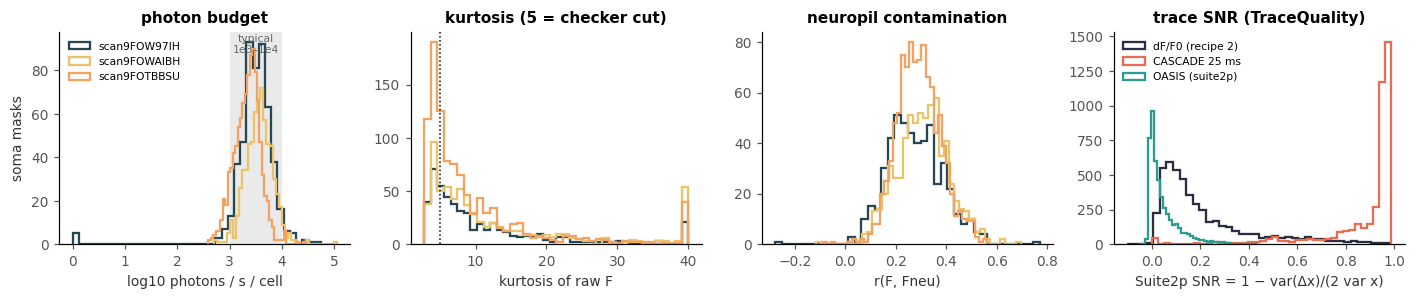

In [8]:
qc = (r.Quality.Cell * imaging.MaskClassification.MaskType).fetch(format="frame").reset_index()
tq = (r.TraceQuality.Cell & "fluo_channel = 0").fetch(format="frame").reset_index()
fig, ax = plt.subplots(1, 4, figsize=(13, 2.8))
for s, c in zip((GRAT, IMG, RF), ("#264653", "#e9c46a", "#f4a261")):
    d = qc[(qc.scan_id == s) & (qc.mask_type == "soma")]
    ax[0].hist(np.log10(d.photons_per_s.clip(1)), 40, histtype="step", lw=1.5, color=c, label=s)
    ax[1].hist(d["kurtosis"].clip(0, 40), 40, histtype="step", lw=1.5, color=c)
    ax[2].hist(d.neuropil_r, 40, histtype="step", lw=1.5, color=c)
ax[0].axvspan(3, 4, color="#ccc", alpha=.4, lw=0); ax[0].set(xlabel="log10 photons / s / cell", ylabel="soma masks", title="photon budget")
ax[0].text(3.5, ax[0].get_ylim()[1]*.9, "typical\n1e3–1e4", ha="center", fontsize=7, color="#666")
ax[1].axvline(5, color="k", ls=":", lw=1); ax[1].set(xlabel="kurtosis of raw F", title="kurtosis (5 = checker cut)")
ax[2].set(xlabel="r(F, Fneu)", title="neuropil contamination")
for src in ("dff0_r2", "cascade25", "oasis"):
    ax[3].hist(tq[tq.trace_source == src].snr_s2p, 40, histtype="step", lw=1.5, color=COL[src], label=LBL[src])
ax[3].set(xlabel="Suite2p SNR = 1 − var(Δx)/(2 var x)", title="trace SNR (TraceQuality)")
ax[0].legend(fontsize=7); ax[3].legend(fontsize=7); plt.tight_layout()

> **Pilot note.** `TraceQuality.Cell.noise_nu` in this test schema was computed as 100·median|Δx|·√fps; CASCADE
> defines it with ÷√fps (`cascade2p.utils.calculate_noise_levels`). The code is fixed; this notebook shows
> ν = stored / fps. Suite2p SNR and ν are meaningful on dF/F0; on spike-rate / deconvolved traces they mostly
> measure sparseness.

### What SNR looks like

Three soma cells of the gratings scan at the 95th, 50th and 5th percentile of dF/F0 SNR. Yellow bars are the
grating presentations.

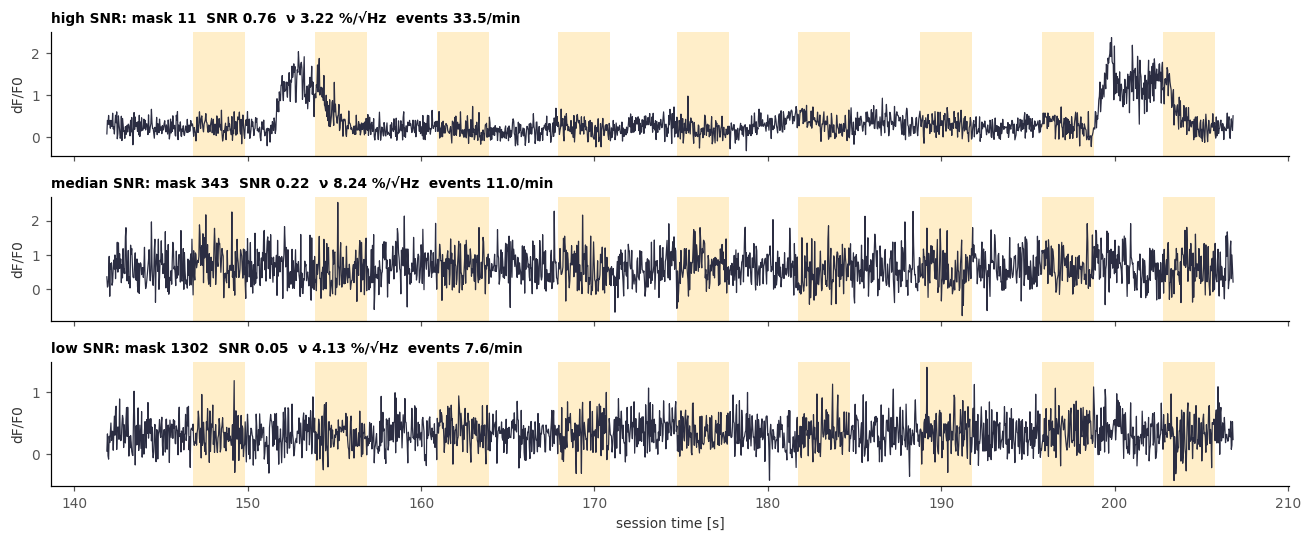

In [9]:
k = CUR[GRAT]; ft = frame_times(k); t0, t1, cond = onsets(k, "gratings")
d = (r.TraceQuality.Cell * imaging.MaskClassification.MaskType & k & {"trace_source": "dff0_r2"} & 'mask_type="soma"' & "fluo_channel=0"
     ).proj("snr_s2p", "noise_nu", "event_rate").fetch(format="frame").reset_index().sort_values("snr_s2p")
pick = [d.iloc[int(q * (len(d) - 1))] for q in (0.95, 0.5, 0.05)]
win = (t0[20] - 5, t0[20] + 60)
fig, axs = plt.subplots(3, 1, figsize=(12, 5), sharex=True)
for ax, row, name in zip(axs, pick, ("high SNR", "median SNR", "low SNR")):
    x = trace(k, row["mask"], "dff0_r2"); n = min(len(x), len(ft)); sel = (ft[:n] > win[0]) & (ft[:n] < win[1])
    for a, b in zip(t0, t1):
        if win[0] < a < win[1]: shade(ax, a, b, COL["stim"], .35)
    ax.plot(ft[:n][sel], x[:n][sel], color=COL["dff0_r2"], lw=.8)
    nu = row.noise_nu / (1 / np.median(np.diff(ft)))   # pilot rows used ×√fps instead of ÷√fps (fixed in code): ν = stored / fps
    ax.set_ylabel("dF/F0"); ax.set_title(f"{name}: mask {int(row['mask'])}  SNR {row.snr_s2p:.2f}  ν {nu:.2f} %/√Hz  "
                                         f"events {row.event_rate:.1f}/min", loc="left", fontsize=9)
axs[-1].set_xlabel("session time [s]"); plt.tight_layout()

## 3. One cell, three trace types

dF/F0 (left axis) with the CASCADE spike-rate estimate and the OASIS deconvolution (right axis, scaled) for the
strongly responsive (ZETA p < 1e-6) soma cell with the cleanest dF/F0. All three are rows of the same key
structure: only `trace_source` differs. This cell is instructive: its activity rises in the gap *before* a grating
and peaks at onset — tightly locked to the stimulus schedule, so ZETA calls it responsive, while a window test of
"stimulus vs 0.5 s before" would call it suppressed.

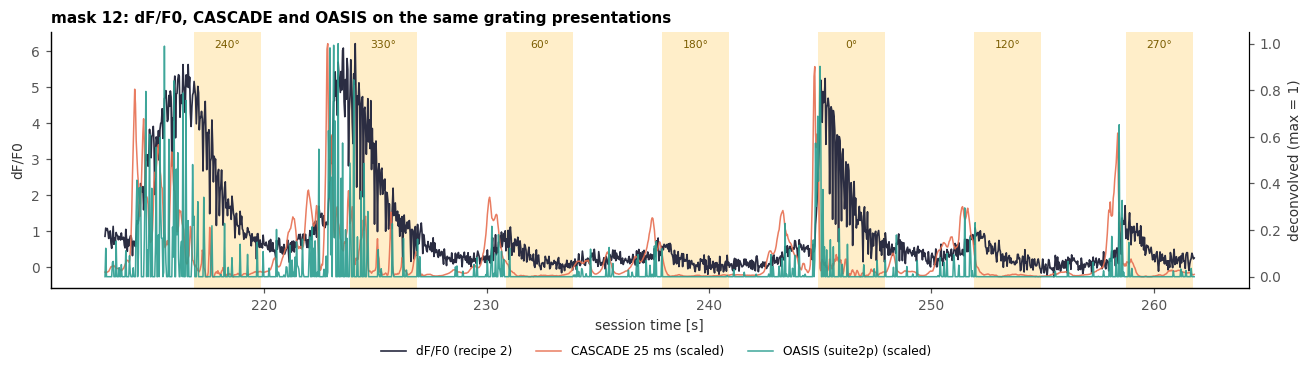

In [10]:
z = (r.Zeta.Cell * imaging.MaskClassification.MaskType * (r.TraceQuality.Cell & {"trace_source": "dff0_r2"}).proj(snr="snr_s2p")
     & k & {"event_selector": "gratings", "zeta_idx": 1, "trace_source": "dff0_r2"} & 'mask_type="soma"' & "fluo_channel=0" & "zeta_p < 1e-6"
     ).proj("zeta_p", "snr").fetch(format="frame").reset_index()
best = int(z.sort_values("snr", ascending=False).iloc[0]["mask"])     # strongly responsive soma cell with the cleanest dF/F0
X = {s: trace(k, best, s) for s in ("dff0_r2", "cascade25", "oasis")}
win = (t0[30] - 4, t0[30] + 45)
n = min(len(ft), *(len(v) for v in X.values())); sel = (ft[:n] > win[0]) & (ft[:n] < win[1])
fig, ax = plt.subplots(figsize=(12, 3.2)); ax2 = ax.twinx()
for a, b, c in zip(t0, t1, cond):
    if win[0] < a < win[1]:
        shade(ax, a, b, COL["stim"], .35); ax.text((a + b) / 2, .97, f"{c}°", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=7, color="#7a5c00")
ax.plot(ft[:n][sel], X["dff0_r2"][:n][sel], color=COL["dff0_r2"], lw=1.1, label=LBL["dff0_r2"])
for s in ("cascade25", "oasis"):
    v = X[s][:n][sel]; ax2.plot(ft[:n][sel], v / np.nanmax(v), color=COL[s], lw=1, alpha=.9, label=LBL[s] + " (scaled)")
ax.set(xlabel="session time [s]", ylabel="dF/F0"); ax2.set_ylabel("deconvolved (max = 1)"); ax2.spines["right"].set_visible(True)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
fig.legend(h1 + h2, l1 + l2, loc="lower center", bbox_to_anchor=(.5, -.06), fontsize=8, ncol=3)
ax.set_title(f"mask {best}: dF/F0, CASCADE and OASIS on the same grating presentations", loc="left"); plt.tight_layout()

## 4. ZETA: does a cell respond, whatever the response shape?

`Zeta` runs the time-series ZETA test (Montijn et al. 2021) with the audit settings (window = median
onset-to-onset interval, 100 resamples). No response window is chosen, so it catches sustained, transient,
OFF and suppressed responses alike. Below: the most and the least responsive soma cells, as trial rasters
and PSTHs on all three trace types. Note the most responsive grating cell: its response starts *after* the
grating ends — an OFF response that a window inside the stimulus would miss, and that ZETA finds without any
window choice (its latency marks the peak).

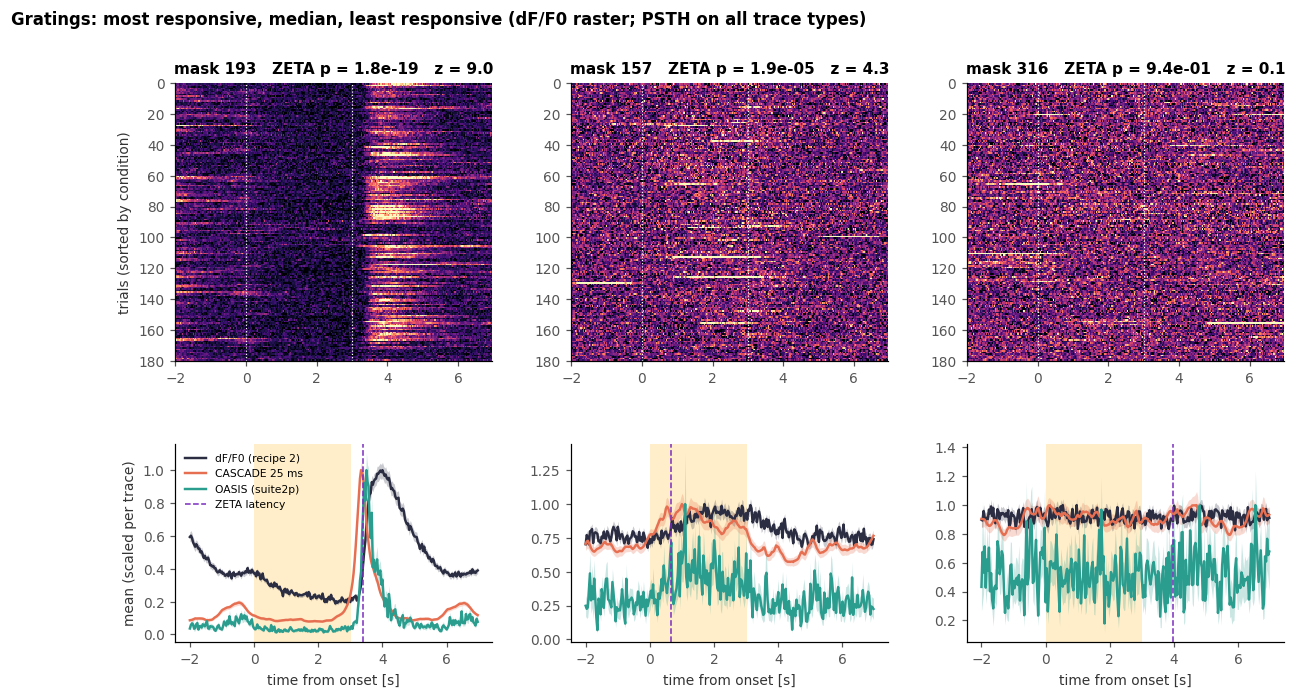

In [11]:
def zeta_examples(k, selector, pre, post, title):
    ft = frame_times(k); t0, t1, cond = onsets(k, selector)
    z = (r.Zeta.Cell * imaging.MaskClassification.MaskType & k & {"event_selector": selector, "zeta_idx": 1, "trace_source": "dff0_r2"}
         & 'mask_type="soma"' & "fluo_channel=0").fetch(format="frame").reset_index().dropna(subset=["zeta_p"]).sort_values("zeta_p")
    rows = [z.iloc[0], z.iloc[len(z) // 2], z.iloc[-1]]
    fig = plt.figure(figsize=(13, 6.6)); gs = GridSpec(2, 3, figure=fig, height_ratios=[1.4, 1], hspace=.35, wspace=.25)
    dur = np.nanmedian(t1 - t0)
    for j, row in enumerate(rows):
        m = int(row["mask"]); grid, M = peri(trace(k, m, "dff0_r2"), ft, t0, pre, post)
        ax = fig.add_subplot(gs[0, j]); order = np.argsort(cond, kind="stable")
        vmax = np.nanpercentile(M, 99)
        ax.imshow(M[order], aspect="auto", cmap="magma", extent=(grid[0], grid[-1], len(M), 0), vmin=0, vmax=vmax, interpolation="nearest")
        ax.axvline(0, color="w", lw=.8, ls=":"); ax.axvline(dur, color="w", lw=.8, ls=":")
        ax.set(title=f"mask {m}   ZETA p = {row.zeta_p:.1e}   z = {row.zeta_z:.1f}", ylabel="trials (sorted by condition)" if j == 0 else "")
        ax2 = fig.add_subplot(gs[1, j]); shade(ax2, 0, dur, COL["stim"], .35)
        for s in ("dff0_r2", "cascade25", "oasis"):
            g, Ms = peri(trace(k, m, s), ft, t0, pre, post)
            sc = np.nanmax(np.abs(np.nanmean(Ms, 0))) or 1
            psth(ax2, g, Ms / sc, COL[s], LBL[s])
        if np.isfinite(row.latency): ax2.axvline(row.latency, color=COL["accent"], lw=1, ls="--", label="ZETA latency")
        ax2.set(xlabel="time from onset [s]", ylabel="mean (scaled per trace)" if j == 0 else "")
        if j == 0: ax2.legend(fontsize=7)
    fig.suptitle(title, x=.01, ha="left", fontweight="bold"); plt.show()

zeta_examples(CUR[GRAT], "gratings", 2, 7, "Gratings: most responsive, median, least responsive (dF/F0 raster; PSTH on all trace types)")

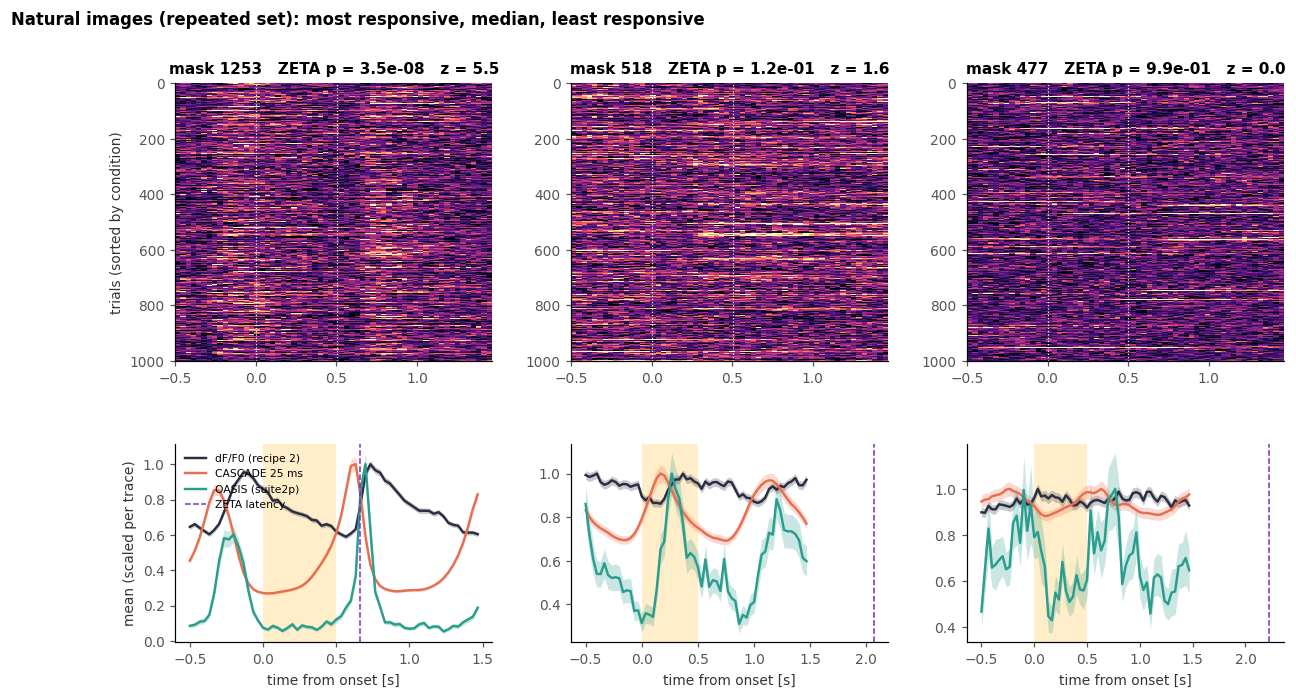

In [12]:
zeta_examples(CUR[IMG], "nat_images_repeated", 0.5, 1.5, "Natural images (repeated set): most responsive, median, least responsive")

### Calibration: real onsets vs random onsets, and agreement with the audit

The `*_random` selectors move every onset to a seeded random time (same count). Their ZETA p-values must be
uniform, so the fraction below 0.05 is the false-positive rate. Right: our ZETA p against the v1-drift-audit's
own run (`artefacts/t73`), same traces, same events, independent code.

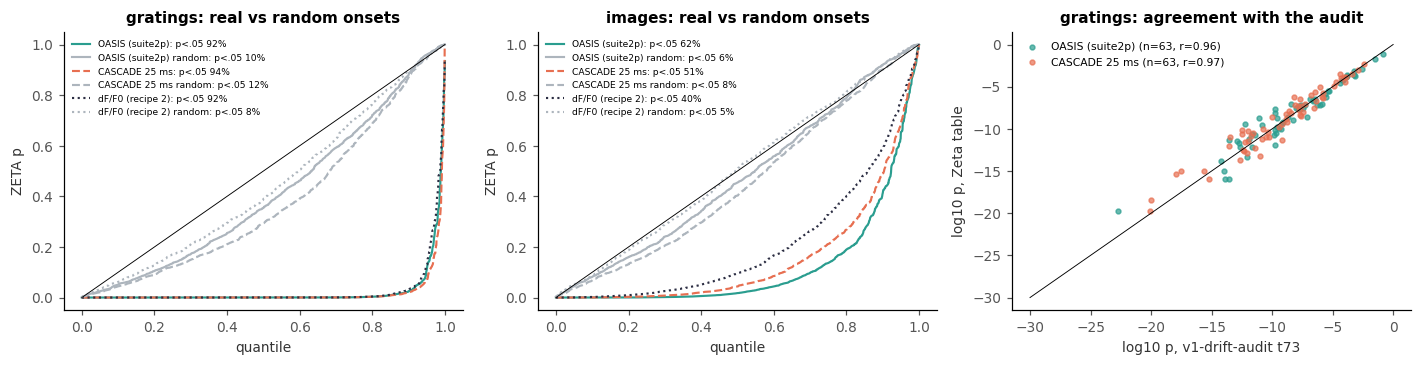

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for j, (scan, sel, rsel, par) in enumerate([(GRAT, "gratings", "gratings_random", "gratings"), (IMG, "nat_images_repeated", "nat_images_repeated_random", "images")]):
    for src, ls in (("oasis", "-"), ("cascade25", "--"), ("dff0_r2", ":")):
        for s_, col in ((sel, COL[src]), (rsel, COL["null"])):
            p = np.sort((r.Zeta.Cell & {"scan_id": scan, "event_selector": s_, "zeta_idx": 1, "trace_source": src} & "fluo_channel=0").fetch("zeta_p"))
            p = p[np.isfinite(p)]
            if len(p): ax[j].plot(np.linspace(0, 1, len(p)), p, ls=ls, color=col, lw=1.4,
                                  label=f"{LBL[src]}{' random' if s_ == rsel else ''}: p<.05 {np.mean(p < .05):.0%}")
    ax[j].plot([0, 1], [0, 1], color="k", lw=.6); ax[j].set(xlabel="quantile", ylabel="ZETA p", title=f"{par}: real vs random onsets"); ax[j].legend(fontsize=6)
A = pd.read_csv(os.path.expanduser("~/resp_pilot/t73/zeta_gratings_scan9FOW97IH.tsv"), sep="\t")
for src in ("oasis", "cascade25"):
    z = (r.Zeta.Cell & {"scan_id": GRAT, "event_selector": "gratings", "zeta_idx": 1, "trace_source": src} & "fluo_channel=0").fetch(format="frame").reset_index()
    m = z.merge(A[A.signal == src][["mask", "zeta_p"]], on="mask", suffixes=("", "_audit"))
    ax[2].scatter(np.log10(m.zeta_p_audit.clip(1e-30)), np.log10(m.zeta_p.clip(1e-30)), s=10, color=COL[src], alpha=.7,
                  label=f"{LBL[src]} (n={len(m)}, r={np.corrcoef(np.log10(m.zeta_p_audit.clip(1e-30)), np.log10(m.zeta_p.clip(1e-30)))[0,1]:.2f})")
ax[2].plot([-30, 0], [-30, 0], color="k", lw=.6); ax[2].set(xlabel="log10 p, v1-drift-audit t73", ylabel="log10 p, Zeta table", title="gratings: agreement with the audit")
ax[2].legend(fontsize=7); plt.tight_layout()

## 5. Read-outs: the PSTH window is a key, not a hidden choice

`ReadoutParamSet` names the window edges (stimulus onset or end + seconds or frames), the baseline, the
measure and the baseline correction. Below, one cell with three read-outs drawn on its PSTH, and the per-cell
values of two of them against each other. Read-out 2 reproduces the Leon export exactly (frames from the
nearest onset frame, first-trial length, matched control window).

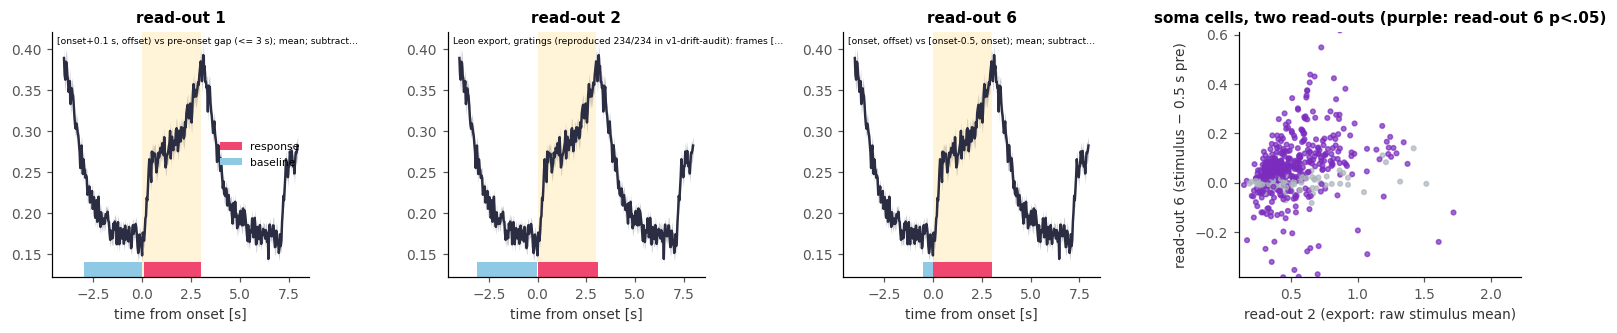

In [14]:
k = CUR[GRAT]; ft = frame_times(k); t0, t1, cond = onsets(k, "gratings")
ro = r.ReadoutParamSet.fetch(format="frame")
best = int((r.Readout.Cell * imaging.MaskClassification.MaskType & k & {"event_selector": "gratings", "trace_source": "dff0_r2", "readout_idx": 6}
            & 'mask_type="soma"' & "fluo_channel=0").proj("effect_d").fetch(format="frame").reset_index().sort_values("effect_d", ascending=False).iloc[0]["mask"])
grid, M = peri(trace(k, best, "dff0_r2"), ft, t0, 4, 8); dur = np.nanmedian(t1 - t0); fps = 1 / np.median(np.diff(ft))
fig, ax = plt.subplots(1, 4, figsize=(14, 3.1), gridspec_kw={"width_ratios": [1, 1, 1, 1.1]})
for a, idx in zip(ax[:3], (1, 2, 6)):
    p = ro.loc[idx]; psth(a, grid, M, COL["dff0_r2"]); shade(a, 0, dur, COL["stim"], .25)
    f = (lambda v: v / fps) if p.window_unit == "frames" else (lambda v: v)
    rs = f(p.resp_start) + (dur if p.resp_start_ref == "offset" else 0); re_ = f(p.resp_stop) + (dur if p.resp_stop_ref == "offset" else 0)
    if p.length_rule == "first_onset" and p.window_unit == "frames": re_ = rs + (np.round(dur * fps) + p.resp_stop) / fps
    a.axvspan(rs, re_, ymin=0, ymax=.06, color=COL["resp"], lw=0, label="response")
    if p.base_mode == "matched":
        b1 = f(p.base_stop); a.axvspan(b1 - (re_ - rs), b1, ymin=0, ymax=.06, color=COL["base"], lw=0, label="baseline")
    elif p.base_mode == "fixed":
        a.axvspan(f(p.base_start), f(p.base_stop), ymin=0, ymax=.06, color=COL["base"], lw=0, label="baseline")
    elif p.base_mode == "gap":
        a.axvspan(-min(abs(p.base_start), np.median(t0[1:] - t1[:-1])), 0, ymin=0, ymax=.06, color=COL["base"], lw=0, label="baseline")
    a.set(title=f"read-out {idx}", xlabel="time from onset [s]"); a.text(0.02, .98, p.readout_desc[:70] + "…", transform=a.transAxes, va="top", fontsize=6, wrap=True)
ax[0].legend(fontsize=7, loc="center right")
v = (r.Readout.Cell * imaging.MaskClassification.MaskType & k & {"event_selector": "gratings", "trace_source": "dff0_r2"} & 'mask_type="soma"' & "fluo_channel=0"
     ).proj("resp", "resp_p").fetch(format="frame").reset_index()
w = v.pivot(index="mask", columns="readout_idx", values="resp")
sig = v[v.readout_idx == 6].set_index("mask").resp_p.reindex(w.index) < .05
ax[3].scatter(w[2], w[6], s=9, c=np.where(sig, COL["accent"], COL["null"]), alpha=.7)
ax[3].set(xlim=np.nanpercentile(w[2], [1, 99]), ylim=np.nanpercentile(w[6], [1, 99]), xlabel="read-out 2 (export: raw stimulus mean)",
          ylabel="read-out 6 (stimulus − 0.5 s pre)", title="soma cells, two read-outs (purple: read-out 6 p<.05)")
plt.tight_layout()

### Which read-out tests can be trusted? The random-onset controls answer it

Every read-out also ran on the random-onset selectors, where no stimulus is time-locked. The fraction of cells
with `resp_p < 0.05` should be ≈ 5 %. It is for dF/F0 with a short pre-window, but **a Wilcoxon test between a
long response window and a short baseline on sparse, non-negative deconvolved traces is badly anti-conservative**
(the baseline is mostly exactly 0). Read-out 3 has no baseline and tests against 0, which is meaningless for
non-negative traces. ZETA, in comparison, stays near nominal. This is the kind of check the key structure makes
cheap: same tables, one more selector.

In [15]:
rp = (r.Readout.Cell * imaging.MaskClassification.MaskType & 'mask_type="soma"' & "fluo_channel=0").proj("resp_p").fetch(format="frame").reset_index()
rp["kind"] = np.where(rp.event_selector.str.endswith("_random"), "random onsets", "real onsets")
rp["paradigm"] = rp.event_selector.str.replace("_random", "")
tab = rp.groupby(["paradigm", "readout_idx", "trace_source", "kind"]).resp_p.apply(lambda p: np.mean(p < .05)).unstack("kind").mul(100).round(1)
zp = (r.Zeta.Cell * imaging.MaskClassification.MaskType & 'mask_type="soma"' & "fluo_channel=0" & "zeta_idx=1").proj("zeta_p").fetch(format="frame").reset_index()
zp["kind"] = np.where(zp.event_selector.str.endswith("_random"), "random onsets", "real onsets"); zp["paradigm"] = zp.event_selector.str.replace("_random", "")
zt = zp.groupby(["paradigm", "trace_source", "kind"]).zeta_p.apply(lambda p: np.mean(p < .05)).unstack("kind").mul(100).round(1)
zt.index = pd.MultiIndex.from_tuples([(a, "ZETA", b) for a, b in zt.index], names=tab.index.names)
out = pd.concat([tab, zt]).sort_index()
out.style.background_gradient(subset=["random onsets"], cmap="Reds", vmin=0, vmax=30).format("{:.1f} %").set_caption("% of soma cells with p < 0.05")

## 6. Stimulus-specific: orientation and direction tuning of gratings

`DirectionTuning` reads the per-trial responses of a `Readout` (here read-out 6: [onset, offset) minus
0.5 s before onset, on dF/F0) and computes the measures Mazurek, Kager & Van Hooser (2014) recommend:
1 − CirVar (orientation), 1 − DirCirVar (direction), Hotelling's T² for orientation, the direction
dot-product test, and a constrained double-Gaussian fit. Classic OSI/DSI are kept for comparison.

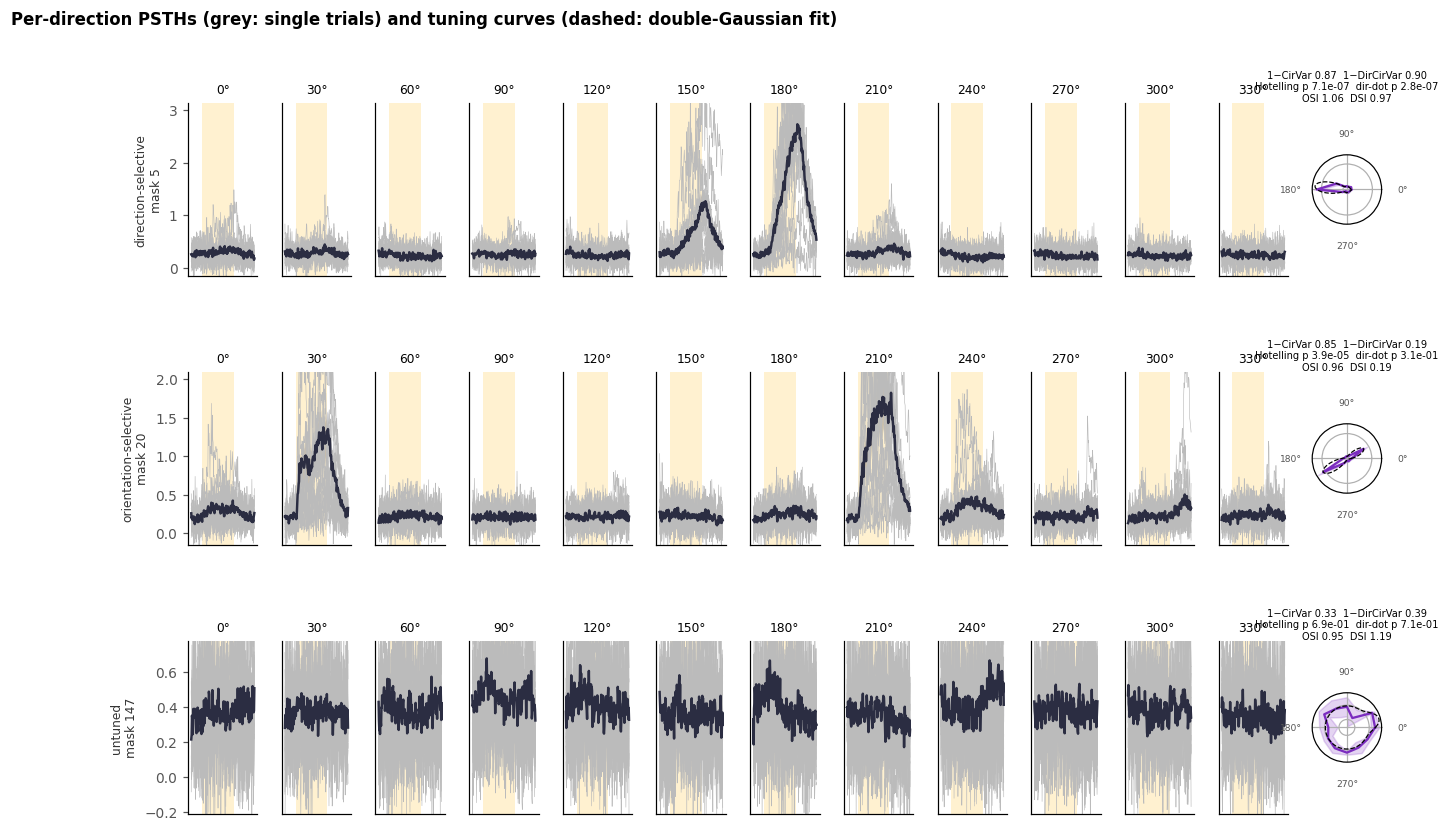

In [16]:
dt = (r.DirectionTuning.Cell * imaging.MaskClassification.MaskType & {"scan_id": GRAT, "event_selector": "gratings", "readout_idx": 6,
       "tuning_idx": 1, "trace_source": "dff0_r2"} & 'mask_type="soma"' & "fluo_channel=0").fetch(format="frame").reset_index()
snr = (r.TraceQuality.Cell & {"scan_id": GRAT, "trace_source": "dff0_r2"} & "fluo_channel=0").proj("snr_s2p").fetch(format="frame").reset_index()[["mask", "snr_s2p"]]
dt = dt.merge(snr, on="mask"); good = (dt.r_pref > 0) & (dt.snr_s2p > dt.snr_s2p.median())
ds = dt[good & (dt.hotelling_p < .01) & (dt.dir_dot_p < .01) & (dt.fit_r2 > .7) & dt.dsi.between(0, 1)].sort_values("dir_vec", ascending=False)
os_ = dt[good & (dt.hotelling_p < .01) & (dt.dir_dot_p > .3) & dt.osi.between(0, 1) & dt.dsi.between(-.3, .3) & (dt.fit_r2 > .5)].sort_values("ori_vec", ascending=False)
un = dt[good & (dt.hotelling_p > .5) & (dt.dir_dot_p > .3)].sort_values("ori_vec")
examples = [("direction-selective", ds.iloc[0]), ("orientation-selective", (os_ if len(os_) else dt[good & (dt.hotelling_p < .01)].sort_values("dir_vec")).iloc[0]),
            ("untuned", un.iloc[len(un) // 2])]
dirs = np.arange(0, 360, 30)
fig = plt.figure(figsize=(14, 8.4)); gs = GridSpec(3, 13, figure=fig, hspace=.55, wspace=.35)
for i, (name, row) in enumerate(examples):
    m = int(row["mask"]); x = trace(k, m, "dff0_r2"); grid, M = peri(x, ft, t0, 1, 5)
    tr = np.asarray((r.Readout.Cell & k & {"event_selector": "gratings", "trace_source": "dff0_r2", "readout_idx": 6, "mask": m, "fluo_channel": 0}).fetch1("trial_resp"), float)
    ymax = np.nanmax([np.nanmean(M[cond == str(d)], 0).max() for d in dirs]) * 1.15
    for j, d in enumerate(dirs):
        ax = fig.add_subplot(gs[i, j]); shade(ax, 0, np.nanmedian(t1 - t0), COL["stim"], .3)
        Mi = M[cond == str(d)]; ax.plot(grid, Mi.T, color="#bbb", lw=.4); psth(ax, grid, Mi, COL["dff0_r2"])
        ax.set_ylim(np.nanmin(M) * 0.5, ymax); ax.set_xticks([]); ax.set_title(f"{d}°", fontsize=8, fontweight="normal")
        if j: ax.set_yticks([])
        else: ax.set_ylabel(f"{name}\nmask {m}", fontsize=8)
    ax = fig.add_subplot(gs[i, 12], projection="polar")
    mean = np.array([np.nanmean(tr[cond == str(d)]) for d in dirs]); sem = np.array([np.nanstd(tr[cond == str(d)]) / np.sqrt(15) for d in dirs])
    th = np.deg2rad(np.r_[dirs, dirs[:1]]); ax.plot(th, np.r_[mean, mean[:1]], color=COL["accent"], lw=1.5)
    ax.fill_between(th, np.r_[mean - sem, (mean - sem)[:1]], np.r_[mean + sem, (mean + sem)[:1]], color=COL["accent"], alpha=.2)
    if np.isfinite(row.fit_pref_dir):
        tt = np.linspace(0, 360, 361); dd = lambda a: (a + 180) % 360 - 180
        fit = row.fit_c + row.fit_rp * np.exp(-dd(tt - row.fit_pref_dir) ** 2 / (2 * row.fit_sigma ** 2)) + row.fit_rn * np.exp(-dd(tt - row.fit_pref_dir + 180) ** 2 / (2 * row.fit_sigma ** 2))
        ax.plot(np.deg2rad(tt), fit, color="k", lw=.8, ls="--")
    ax.set_xticks(np.deg2rad([0, 90, 180, 270])); ax.set_yticklabels([]); ax.tick_params(labelsize=6)
    ax.set_title(f"1−CirVar {row.ori_vec:.2f}  1−DirCirVar {row.dir_vec:.2f}\nHotelling p {row.hotelling_p:.1e}  dir-dot p {row.dir_dot_p:.1e}\nOSI {row.osi:.2f}  DSI {row.dsi:.2f}",
                 fontsize=6.5, fontweight="normal", pad=18)
fig.suptitle("Per-direction PSTHs (grey: single trials) and tuning curves (dashed: double-Gaussian fit)", x=.01, ha="left", fontweight="bold"); plt.show()

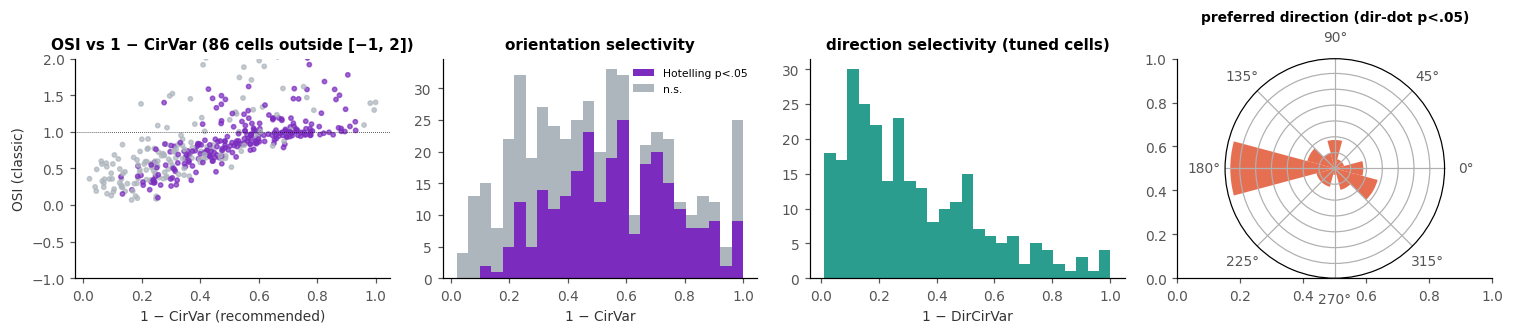

In [17]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3.1))
sig = dt.hotelling_p < .05
ax[0].scatter(dt.ori_vec, dt.osi, s=8, c=np.where(sig, COL["accent"], COL["null"]), alpha=.7)
out_ = int(np.sum(~dt.osi.between(-1, 2))); ax[0].set_ylim(-1, 2); ax[0].axhline(1, color="k", lw=.5, ls=":")
ax[0].set(xlabel="1 − CirVar (recommended)", ylabel="OSI (classic)", title=f"OSI vs 1 − CirVar ({out_} cells outside [−1, 2])")
ax[1].hist([dt.ori_vec[sig], dt.ori_vec[~sig]], 25, stacked=True, color=[COL["accent"], COL["null"]], label=["Hotelling p<.05", "n.s."])
ax[1].set(xlabel="1 − CirVar", title="orientation selectivity"); ax[1].legend(fontsize=7)
ax[2].hist(dt.dir_vec[sig], 25, color=COL["oasis"]); ax[2].set(xlabel="1 − DirCirVar", title="direction selectivity (tuned cells)")
ax3 = plt.subplot(1, 4, 4, projection="polar")
pd_ = np.deg2rad(dt.pref_dir_dot[sig & (dt.dir_dot_p < .05)].dropna()); ax3.hist(pd_, bins=np.deg2rad(np.arange(-15, 360, 30)), color=COL["cascade25"])
ax3.set_title("preferred direction (dir-dot p<.05)", fontsize=9); ax3.set_yticklabels([]); plt.tight_layout()

## 7. Natural images: reliability on the repeated set

On the 100 repeated images, `Readout` stores per-trial responses and the leave-one-repeat-out **oracle**
correlation and **response SNR** (signal variance / noise variance across image means; v1-drift-audit
definitions). Left: the most reliable cell, image × repeat. Middle: its 100-image response curve, two halves
of the repeats against each other. Right: oracle across cells for the three trace types.

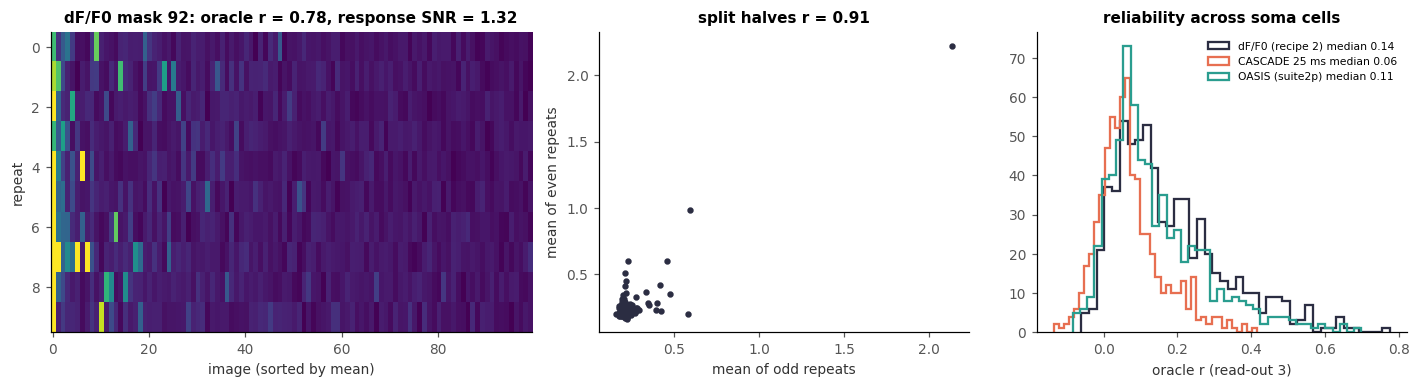

In [18]:
k = CUR[IMG]; t0, t1, cond = onsets(k, "nat_images_repeated")
ro_ = (r.Readout.Cell * imaging.MaskClassification.MaskType & k & {"event_selector": "nat_images_repeated", "readout_idx": 3} & 'mask_type="soma"' & "fluo_channel=0"
       ).fetch(format="frame").reset_index()
b = ro_[ro_.trace_source == "dff0_r2"].sort_values("oracle_r", ascending=False).iloc[0]
tr = np.asarray(b.trial_resp, float); imgs = np.unique(cond)
R = np.vstack([tr[cond == i][:10] for i in imgs]); o = np.argsort(R.mean(1))[::-1]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.3, 1, 1]})
ax[0].imshow(R[o].T, aspect="auto", cmap="viridis", interpolation="nearest", vmin=np.nanpercentile(R, 1), vmax=np.nanpercentile(R, 99))
ax[0].set(xlabel="image (sorted by mean)", ylabel="repeat", title=f"dF/F0 mask {int(b['mask'])}: oracle r = {b.oracle_r:.2f}, response SNR = {b.response_snr:.2f}")
h1, h2 = R[:, ::2].mean(1), R[:, 1::2].mean(1)
ax[1].scatter(h1, h2, s=10, color=COL["dff0_r2"]); ax[1].set(xlabel="mean of odd repeats", ylabel="mean of even repeats", title=f"split halves r = {np.corrcoef(h1, h2)[0,1]:.2f}")
for src in ("dff0_r2", "cascade25", "oasis"):
    ax[2].hist(ro_[ro_.trace_source == src].oracle_r.dropna(), 40, histtype="step", lw=1.5, color=COL[src], label=f"{LBL[src]} median {ro_[ro_.trace_source == src].oracle_r.median():.2f}")
ax[2].set(xlabel="oracle r (read-out 3)", title="reliability across soma cells"); ax[2].legend(fontsize=7); plt.tight_layout()

## 8. Receptive fields from the same tables

The checkerboard selector labels each onset with the patch position (`azimuth|elevation`, Bonsai fields 2
and 3). In this protocol the positions form a **cross**: an azimuth sweep at elevation 15° and an elevation
sweep at azimuth 0°, so each cell has two 1D profiles rather than a 2D map. `Readout.Condition` already holds
them (mean ± SEM per position); no RF-specific code was needed, and an RF follow-up table (centre and width
fits) would read exactly these rows. In this pilot scan the RF responses on dF/F0 are weak and noisy (4 repeats
per position): the panels show the mechanics, not clean receptive fields.

positions: 70  (azimuth sweep at elevation 15°, elevation sweep at azimuth 0°)


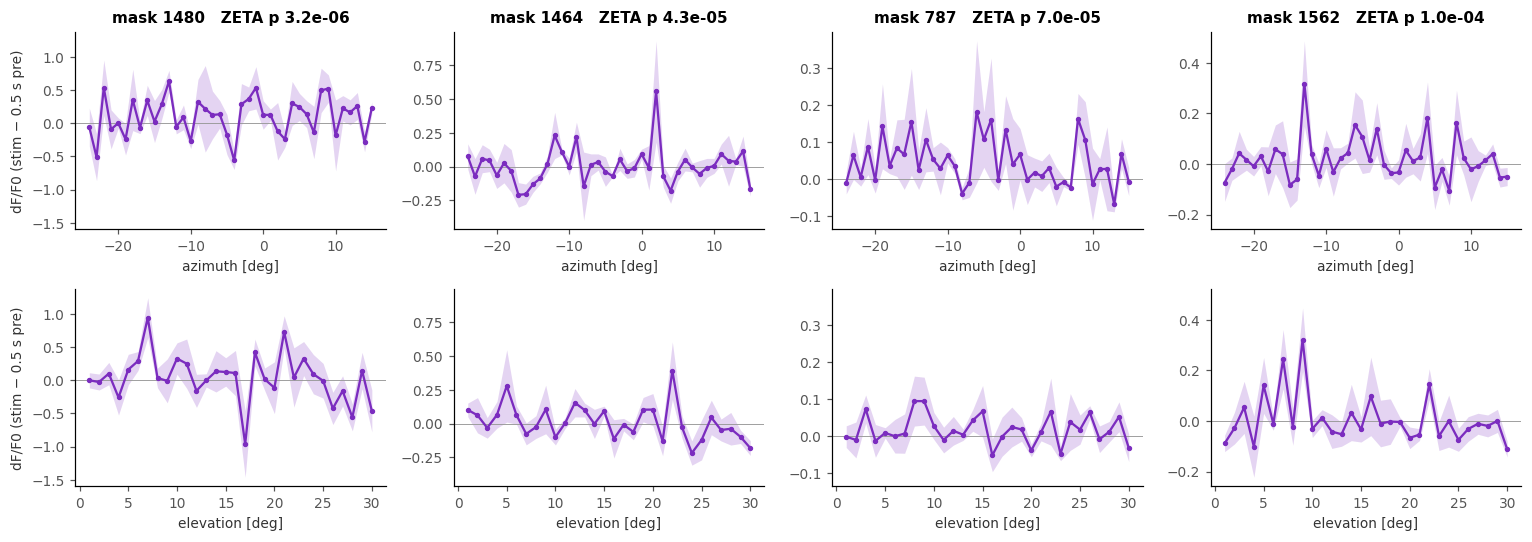

In [19]:
k = CUR[RF]
cc = (r.Readout.Condition & k & {"event_selector": "rf_checkerboard", "readout_idx": 6, "trace_source": "dff0_r2"} & "fluo_channel=0").fetch(format="frame").reset_index()
cc[["az", "el"]] = cc.condition.str.split("|", expand=True).astype(float)
el0 = cc.el.mode().iloc[0]; az0 = cc.az.mode().iloc[0]
zc = (r.Zeta.Cell * imaging.MaskClassification.MaskType & k & {"event_selector": "rf_checkerboard", "zeta_idx": 1, "trace_source": "dff0_r2"}
      & 'mask_type="soma"' & "fluo_channel=0").proj("zeta_p").fetch(format="frame").reset_index()
top = zc.sort_values("zeta_p").head(4)["mask"].astype(int).tolist()
print(f"positions: {cc.condition.nunique()}  (azimuth sweep at elevation {el0:g}°, elevation sweep at azimuth {az0:g}°)")
fig, ax = plt.subplots(2, 4, figsize=(14, 5), sharey="col")
for j, m in enumerate(top):
    d = cc[cc["mask"] == m]
    for i, (sweep, axis, fixed, lab) in enumerate([(d[d.el == el0], "az", el0, "azimuth"), (d[d.az == az0], "el", az0, "elevation")]):
        sw = sweep.sort_values(axis); a = ax[i, j]
        a.axhline(0, color="#999", lw=.6); a.fill_between(sw[axis], sw.resp - sw.resp_sem, sw.resp + sw.resp_sem, color=COL["accent"], alpha=.2, lw=0)
        a.plot(sw[axis], sw.resp, color=COL["accent"], lw=1.5, marker="o", ms=2.5)
        a.set(xlabel=f"{lab} [deg]", ylabel="dF/F0 (stim − 0.5 s pre)" if j == 0 else "")
    ax[0, j].set_title(f"mask {m}   ZETA p {zc.set_index('mask').loc[m, 'zeta_p']:.1e}")
plt.tight_layout()

## 9. Decisions: named thresholds, applied by query

`CellRule` stores thresholds as a row bound to a trace type, a ZETA variant and a read-out; `cells(rule)`
applies them on both levels at query time (nothing is stored, so a new threshold never requires recomputing).
The equivalent query is written out below with DataJoint operators so it runs without the Python package.

In [20]:
rule = r.CellRule.fetch(format="frame"); display(rule)
q = (r.Quality.Cell.proj("kurtosis", "photons_per_s") * (r.TraceQuality.Cell & {"trace_source": "dff0_r2"}).proj("snr_s2p", "max_value")
     * (r.Zeta.Cell & {"zeta_idx": 2, "trace_source": "dff0_r2"}).proj("zeta_p", "condition_p") * (imaging.MaskClassification.MaskType & 'mask_type="soma"'))
flags = q.proj(is_qc="kurtosis >= 5", is_active="snr_s2p >= 0.2", is_responsive="zeta_p < 0.05", is_specific="condition_p < 0.05").fetch(format="frame").reset_index()
s = flags.groupby("event_selector")[["is_qc", "is_active", "is_responsive", "is_specific"]].mean().mul(100).round(1)
s["soma cells"] = flags.groupby("event_selector").size(); s

,trace_source,readout_idx,zeta_idx,mask_type,max_trace_value,min_kurtosis,min_photons_per_s,min_snr_s2p,max_zeta_p,max_resp_p,max_condition_p,min_oracle_r,rule_note
cell_rule,,,,,,,,,,,,,
zeta05_dff0,dff0_r2,None,2,,NaN,NaN,NaN,NaN,0.05,NaN,0.05,NaN,dF/F0 recipe 2: ZETA p < 0.05 pooled; Holm per...


,is_qc,is_active,is_responsive,is_specific,soma cells
event_selector,,,,,
gratings,74.257426,56.078431,91.568627,66.27451,510
gratings_random,74.257426,56.078431,6.078431,NaN,510


## 10. Recipes

```python
# every responsive soma cell of a curation, on CASCADE, with its preferred grating direction and tuning
q = (r.Zeta.Cell & {"trace_source": "cascade25", "event_selector": "gratings", "zeta_idx": 1} & "zeta_p < 0.01") \
    * (r.DirectionTuning.Cell & {"readout_idx": 6, "tuning_idx": 1}).proj("ori_vec", "dir_vec", "hotelling_p", "fit_pref_dir")

# per-trial responses of one cell, with the trial (block) and stimulus string of every onset
tr = (r.Readout.Cell & key & {"readout_idx": 6}).fetch1("trial_resp")
on = (r.EventSet.Onset * trial.Trial * event.Event & key).fetch("onset_idx", "trial_id", "event_type", "event_start_time", order_by="onset_idx")

# stage a new analysis: CASCADE 25 + OASIS, gratings, 0.5 s pre / [onset, stim end) mean, pooled + per-direction ZETA, tuning
from adamacs.schemas import responsiveness as resp
resp.plan_tasks(curations, ["cascade25", "oasis"], ["gratings"], readouts=[6], zetas=[1, 2], owner="me", tunings=[(6, 1)])
```